In [1]:
# ============================================================
# TAHAP 1
# IMPORT LIBRARY
# ============================================================

# pandas : mengolah data berbentuk tabel (DataFrame)
import pandas as pd
# numpy : perhitungan matriks dan angka
import numpy as np
# matplotlib : membuat grafik
import matplotlib.pyplot as plt

# pathlib : mengelola lokasi/nama file
from pathlib import Path
# display : menampilkan tabel dengan rapi di Jupyter/Colab
from IPython.display import display
# files : modul khusus Google Colab untuk unggah/unduh file
from google.colab import files

In [2]:
# ============================================================
# TAHAP 2
# UPLOAD DAN MEMBACA DATA MENTAH
# ============================================================

print("Silakan unggah data mentah berformat CSV atau Excel.")

# Membuka jendela unggah file milik Colab
uploaded = files.upload()

# Jika tidak ada file yang dipilih, hentikan proses
if len(uploaded) == 0:
    raise ValueError("Tidak ada file yang diunggah.")

# Jika lebih dari satu file, hanya file pertama yang dipakai
if len(uploaded) > 1:
    print(
        "Terdapat lebih dari satu file. "
        "Sistem akan menggunakan file pertama."
    )

# Mengambil nama file pertama yang diunggah
nama_file = next(iter(uploaded))
# Mengambil ekstensi file (.csv, .xlsx, dst.) dalam huruf kecil
ekstensi = Path(nama_file).suffix.lower()

if ekstensi == ".csv":
    # sep=None memungkinkan pandas mencoba mendeteksi
    # pemisah koma atau titik koma secara otomatis.
    df_mentah = pd.read_csv(
        nama_file,
        sep=None,
        engine="python"
    )

elif ekstensi in [".xlsx", ".xls"]:
    # Membaca file Excel
    df_mentah = pd.read_excel(nama_file)

else:
    # Format selain CSV/Excel ditolak
    raise ValueError(
        "Format file tidak didukung. "
        "Gunakan CSV, XLSX, atau XLS."
    )

# Membersihkan spasi pada nama kolom
df_mentah.columns = (
    df_mentah.columns
    .astype(str)
    .str.strip()
)

# Memastikan tidak terdapat nama kolom duplikat
if df_mentah.columns.duplicated().any():
    kolom_duplikat = (
        df_mentah.columns[
            df_mentah.columns.duplicated()
        ]
        .tolist()
    )

    raise ValueError(
        f"Terdapat nama kolom duplikat: {kolom_duplikat}"
    )

# Menampilkan ringkasan data yang berhasil dibaca
print("\nData berhasil dibaca.")
print(f"Nama file    : {nama_file}")
print(f"Jumlah baris : {len(df_mentah)}")
print(f"Jumlah kolom : {len(df_mentah.columns)}")

print("\nData mentah:")
display(df_mentah)

Silakan unggah data mentah berformat CSV atau Excel.


Saving Latihan Soal_TOPSIS.csv to Latihan Soal_TOPSIS.csv

Data berhasil dibaca.
Nama file    : Latihan Soal_TOPSIS.csv
Jumlah baris : 4
Jumlah kolom : 6

Data mentah:


,Alternatif,C1_Harga,C2_Nilai_Investasi,C3_Daya_Dukung,C4_Prioritas,C5_Ketersediaan
0,A1 Membeli mobil box,420,75,3,1,3
1,A2 Membeli tanah untuk gudang baru,580,220,2,3,2
2,A3 Maintenance sarana TI,350,80,4,2,1
3,A4 Pengembangan produk baru,410,170,3,4,2


In [3]:
# ============================================================
# TAHAP 3
# MEMILIH KOLOM IDENTITAS ALTERNATIF
# ============================================================

def pilih_kolom_alternatif(df):
    """
    Meminta pengguna memilih satu kolom yang menjadi
    identitas atau nama alternatif.
    """

    # Daftar seluruh nama kolom
    daftar_kolom = list(df.columns)

    print("\nPilih kolom yang menjadi identitas alternatif.")
    print("Contoh: Nama Laptop, Nama Pegawai, atau Kode Produk.\n")

    for nomor, kolom in enumerate(daftar_kolom, start=1):
        print(f"{nomor}. {kolom}")

    # Mengulang sampai pengguna memasukkan nomor yang valid
    while True:
        jawaban = input(
            "\nMasukkan nomor kolom alternatif: "
        ).strip()

        try:
            nomor_pilihan = int(jawaban)

            # Nomor valid: kembalikan nama kolom yang dipilih
            if 1 <= nomor_pilihan <= len(daftar_kolom):
                return daftar_kolom[nomor_pilihan - 1]

            print(
                f"Masukkan nomor antara 1 sampai "
                f"{len(daftar_kolom)}."
            )

        except ValueError:
            # Terjadi jika masukan bukan angka
            print("Masukkan nomor kolom yang valid.")


kolom_alternatif = pilih_kolom_alternatif(df_mentah)

print(
    f"\nKolom identitas alternatif yang dipilih: "
    f"{kolom_alternatif}"
)


Pilih kolom yang menjadi identitas alternatif.
Contoh: Nama Laptop, Nama Pegawai, atau Kode Produk.

1. Alternatif
2. C1_Harga
3. C2_Nilai_Investasi
4. C3_Daya_Dukung
5. C4_Prioritas
6. C5_Ketersediaan

Masukkan nomor kolom alternatif: 1

Kolom identitas alternatif yang dipilih: Alternatif


In [4]:
# ============================================================
# TAHAP 4
# MEMILIH KOLOM KRITERIA
# ============================================================

def pilih_kolom_kriteria(df, kolom_alternatif):
    """
    Meminta pengguna memilih kolom-kolom yang
    digunakan sebagai kriteria TOPSIS.
    """

    # Kolom alternatif tidak boleh menjadi kriteria
    kolom_tersedia = [
        kolom
        for kolom in df.columns
        if kolom != kolom_alternatif
    ]

    # Harus tersisa minimal satu kolom untuk dijadikan kriteria
    if len(kolom_tersedia) == 0:
        raise ValueError(
            "Tidak terdapat kolom yang dapat dijadikan kriteria."
        )

    print("\nPilih kolom yang akan digunakan sebagai kriteria.\n")

    for nomor, kolom in enumerate(kolom_tersedia, start=1):
        print(f"{nomor}. {kolom}")

    print("\nMasukkan beberapa nomor dan pisahkan dengan koma.")
    print("Contoh: 1,2,4")

    # Mengulang sampai masukan valid
    while True:
        jawaban = input(
            "\nNomor kolom kriteria: "
        ).strip()

        # Masukan kosong ditolak
        if jawaban == "":
            print("Pilihan kriteria tidak boleh kosong.")
            continue

        try:
            # Memecah masukan "1,2,4" menjadi daftar angka [1, 2, 4]
            daftar_nomor = [
                int(nomor.strip())
                for nomor in jawaban.split(",")
            ]

            # Menghilangkan nomor duplikat,
            # tetapi mempertahankan urutannya.
            daftar_nomor = list(
                dict.fromkeys(daftar_nomor)
            )

            # Mencari nomor yang di luar rentang daftar kolom
            nomor_tidak_valid = [
                nomor
                for nomor in daftar_nomor
                if nomor < 1 or nomor > len(kolom_tersedia)
            ]

            if nomor_tidak_valid:
                print(
                    "Nomor berikut tidak valid:",
                    nomor_tidak_valid
                )
                continue

            # Mengubah nomor menjadi nama kolom
            kriteria_terpilih = [
                kolom_tersedia[nomor - 1]
                for nomor in daftar_nomor
            ]

            return kriteria_terpilih

        except ValueError:
            # Terjadi jika ada masukan yang bukan angka
            print(
                "Format tidak valid. "
                "Gunakan format seperti 1,2,4."
            )


daftar_kriteria = pilih_kolom_kriteria(
    df_mentah,
    kolom_alternatif
)

print("\nKriteria yang dipilih:")

for nomor, kriteria in enumerate(daftar_kriteria, start=1):
    print(f"{nomor}. {kriteria}")


Pilih kolom yang akan digunakan sebagai kriteria.

1. C1_Harga
2. C2_Nilai_Investasi
3. C3_Daya_Dukung
4. C4_Prioritas
5. C5_Ketersediaan

Masukkan beberapa nomor dan pisahkan dengan koma.
Contoh: 1,2,4

Nomor kolom kriteria: 1,2,3,4,5

Kriteria yang dipilih:
1. C1_Harga
2. C2_Nilai_Investasi
3. C3_Daya_Dukung
4. C4_Prioritas
5. C5_Ketersediaan


In [5]:
# ============================================================
# TAHAP 5
# VALIDASI DATA ALTERNATIF DAN KRITERIA
# ============================================================

def validasi_data_topsis(
    df,
    kolom_alternatif,
    daftar_kriteria
):
    """
    Memvalidasi dan membersihkan data yang akan
    digunakan dalam perhitungan TOPSIS.
    """

    # Mengambil hanya kolom alternatif dan kriteria (salinan data)
    data_topsis = df[
        [kolom_alternatif] + daftar_kriteria
    ].copy()

    # Menghapus baris dengan identitas alternatif kosong
    data_topsis = data_topsis.dropna(
        subset=[kolom_alternatif]
    )

    # Mengubah identitas alternatif menjadi teks tanpa spasi berlebih
    data_topsis[kolom_alternatif] = (
        data_topsis[kolom_alternatif]
        .astype(str)
        .str.strip()
    )

    # Mendeteksi identitas kosong setelah spasi dibersihkan
    alternatif_kosong = (
        data_topsis[kolom_alternatif] == ""
    )

    if alternatif_kosong.any():
        raise ValueError(
            "Terdapat identitas alternatif yang kosong."
        )

    # Mendeteksi identitas alternatif duplikat
    baris_duplikat = data_topsis[
        kolom_alternatif
    ].duplicated(keep=False)

    if baris_duplikat.any():
        daftar_duplikat = (
            data_topsis.loc[
                baris_duplikat,
                kolom_alternatif
            ]
            .unique()
            .tolist()
        )

        raise ValueError(
            "Terdapat identitas alternatif duplikat: "
            f"{daftar_duplikat}"
        )

    # Mengubah nilai setiap kriteria menjadi numerik
    # (nilai yang bukan angka menjadi NaN/kosong)
    for kriteria in daftar_kriteria:
        data_topsis[kriteria] = pd.to_numeric(
            data_topsis[kriteria],
            errors="coerce"
        )

    # Memeriksa nilai kosong atau bukan angka
    posisi_error = []

    # Mencatat posisi setiap nilai yang bermasalah
    for indeks, baris in data_topsis.iterrows():
        for kriteria in daftar_kriteria:
            nilai = baris[kriteria]

            if pd.isna(nilai) or not np.isfinite(nilai):
                posisi_error.append({
                    # +2 karena baris 1 di Excel adalah header
                    "Baris Data": indeks + 2,
                    "Alternatif": baris[kolom_alternatif],
                    "Kriteria": kriteria,
                    "Nilai": nilai
                })

    if posisi_error:
        print(
            "\nNilai berikut kosong, bukan angka, "
            "atau bukan angka yang valid:"
        )

        display(pd.DataFrame(posisi_error))

        raise ValueError(
            "Perbaiki data yang ditampilkan di atas."
        )

    # TOPSIS membutuhkan minimal dua alternatif untuk dibandingkan
    if len(data_topsis) < 2:
        raise ValueError(
            "TOPSIS memerlukan sekurang-kurangnya "
            "dua alternatif."
        )

    if len(daftar_kriteria) < 1:
        raise ValueError(
            "Pilih sekurang-kurangnya satu kriteria."
        )

    # Menolak kriteria yang seluruh nilainya nol
    for kriteria in daftar_kriteria:
        # Penyebut normalisasi = akar dari jumlah kuadrat kolom
        penyebut = np.sqrt(
            np.sum(data_topsis[kriteria].to_numpy() ** 2)
        )

        if penyebut == 0:
            raise ValueError(
                f"Seluruh nilai kriteria '{kriteria}' adalah 0. "
                "Kriteria tersebut tidak dapat dinormalisasi."
            )

    # Merapikan nomor indeks agar kembali berurutan dari 0
    return data_topsis.reset_index(drop=True)


df_topsis = validasi_data_topsis(
    df_mentah,
    kolom_alternatif,
    daftar_kriteria
)

print("\nData yang akan diproses menggunakan TOPSIS:")
display(df_topsis)


Data yang akan diproses menggunakan TOPSIS:


,Alternatif,C1_Harga,C2_Nilai_Investasi,C3_Daya_Dukung,C4_Prioritas,C5_Ketersediaan
0,A1 Membeli mobil box,420,75,3,1,3
1,A2 Membeli tanah untuk gudang baru,580,220,2,3,2
2,A3 Maintenance sarana TI,350,80,4,2,1
3,A4 Pengembangan produk baru,410,170,3,4,2


In [6]:
# ============================================================
# TAHAP 6
# MENENTUKAN JENIS SETIAP KRITERIA
# ============================================================

def input_jenis_kriteria(daftar_kriteria):
    """
    Meminta pengguna menentukan benefit atau cost
    untuk setiap kriteria.
    """

    # Kamus: nama kriteria -> "benefit" atau "cost"
    jenis_kriteria = {}

    print("\nPenentuan jenis kriteria:")
    print("B = Benefit, semakin besar semakin baik")
    print("C = Cost, semakin kecil semakin baik")

    for kriteria in daftar_kriteria:
        # Mengulang sampai jawaban valid
        while True:
            jawaban = input(
                f"\nJenis kriteria '{kriteria}' [B/C]: "
            ).strip().lower()

            if jawaban in ["b", "benefit"]:
                jenis_kriteria[kriteria] = "benefit"
                break

            if jawaban in ["c", "cost"]:
                jenis_kriteria[kriteria] = "cost"
                break

            print(
                "Masukkan B untuk benefit "
                "atau C untuk cost."
            )

    return jenis_kriteria


jenis_kriteria = input_jenis_kriteria(
    daftar_kriteria
)

# Tabel jenis setiap kriteria
tabel_jenis = pd.DataFrame({
    "Kriteria": daftar_kriteria,
    "Jenis": [
        jenis_kriteria[kriteria]
        for kriteria in daftar_kriteria
    ]
})

print("\nJenis kriteria:")
display(tabel_jenis)


Penentuan jenis kriteria:
B = Benefit, semakin besar semakin baik
C = Cost, semakin kecil semakin baik

Jenis kriteria 'C1_Harga' [B/C]: c

Jenis kriteria 'C2_Nilai_Investasi' [B/C]: b

Jenis kriteria 'C3_Daya_Dukung' [B/C]: b

Jenis kriteria 'C4_Prioritas' [B/C]: c

Jenis kriteria 'C5_Ketersediaan' [B/C]: b

Jenis kriteria:


,Kriteria,Jenis
0,C1_Harga,cost
1,C2_Nilai_Investasi,benefit
2,C3_Daya_Dukung,benefit
3,C4_Prioritas,cost
4,C5_Ketersediaan,benefit


In [7]:
# ============================================================
# TAHAP 7
# MEMASUKKAN DAN MENORMALISASI BOBOT
# ============================================================

def input_bobot_kriteria(daftar_kriteria):
    """
    Meminta bobot setiap kriteria dan menormalisasinya
    agar jumlah bobot sama dengan 1.
    """

    # Kamus: nama kriteria -> bobot sesuai masukan pengguna
    bobot_awal = {}

    print("\nMasukkan bobot setiap kriteria.")
    print(
        "Bobot boleh menggunakan skala apa pun, "
        "misalnya 5, 4, 3 atau 50, 30, 20."
    )

    for kriteria in daftar_kriteria:
        # Mengulang sampai bobot valid
        while True:
            jawaban = input(
                f"Bobot untuk '{kriteria}': "
            ).strip()

            # Mendukung masukan desimal dengan koma
            jawaban = jawaban.replace(",", ".")

            try:
                nilai_bobot = float(jawaban)

                # Menolak nilai tak hingga atau NaN
                if not np.isfinite(nilai_bobot):
                    print("Bobot harus berupa angka yang valid.")
                    continue

                if nilai_bobot < 0:
                    print("Bobot tidak boleh negatif.")
                    continue

                bobot_awal[kriteria] = nilai_bobot
                break

            except ValueError:
                print("Masukkan bobot dalam bentuk angka.")

    total_bobot = sum(bobot_awal.values())

    if total_bobot <= 0:
        raise ValueError(
            "Total bobot harus lebih besar dari nol."
        )

    # Normalisasi bobot: setiap bobot dibagi total bobot
    # sehingga jumlah seluruh bobot menjadi 1
    bobot_normalisasi = {
        kriteria: bobot_awal[kriteria] / total_bobot
        for kriteria in daftar_kriteria
    }

    return bobot_awal, bobot_normalisasi


bobot_awal, bobot = input_bobot_kriteria(
    daftar_kriteria
)

# Tabel ringkasan: jenis, bobot masukan, dan bobot setelah normalisasi
tabel_konfigurasi = pd.DataFrame({
    "Kriteria": daftar_kriteria,
    "Jenis": [
        jenis_kriteria[kriteria]
        for kriteria in daftar_kriteria
    ],
    "Bobot Masukan": [
        bobot_awal[kriteria]
        for kriteria in daftar_kriteria
    ],
    "Bobot Normalisasi": [
        bobot[kriteria]
        for kriteria in daftar_kriteria
    ]
})

print("\nKonfigurasi kriteria:")
display(tabel_konfigurasi.round(6))

# Total bobot normalisasi seharusnya selalu 1
print(
    "Total bobot normalisasi:",
    round(sum(bobot.values()), 6)
)


Masukkan bobot setiap kriteria.
Bobot boleh menggunakan skala apa pun, misalnya 5, 4, 3 atau 50, 30, 20.
Bobot untuk 'C1_Harga': 20
Bobot untuk 'C2_Nilai_Investasi': 15
Bobot untuk 'C3_Daya_Dukung': 30
Bobot untuk 'C4_Prioritas': 25
Bobot untuk 'C5_Ketersediaan': 10

Konfigurasi kriteria:


,Kriteria,Jenis,Bobot Masukan,Bobot Normalisasi
0,C1_Harga,cost,20.0,0.20
1,C2_Nilai_Investasi,benefit,15.0,0.15
2,C3_Daya_Dukung,benefit,30.0,0.30
3,C4_Prioritas,cost,25.0,0.25
4,C5_Ketersediaan,benefit,10.0,0.10


Total bobot normalisasi: 1.0


In [9]:
# ============================================================
# TAHAP 8
# KONFIRMASI KONFIGURASI TOPSIS
# ============================================================

print("=" * 60)
print("RINGKASAN KONFIGURASI TOPSIS")
print("=" * 60)

print(f"File data         : {nama_file}")
print(f"Kolom alternatif : {kolom_alternatif}")
print(f"Jumlah alternatif: {len(df_topsis)}")
print(f"Jumlah kriteria  : {len(daftar_kriteria)}")

print("\nAlternatif:")
display(df_topsis[[kolom_alternatif]])

print("\nKonfigurasi kriteria:")
display(tabel_konfigurasi.round(6))

# Meminta persetujuan pengguna sebelum perhitungan dilanjutkan
while True:
    konfirmasi = input(
        "\nApakah konfigurasi sudah benar? [Y/T]: "
    ).strip().lower()

    if konfirmasi in ["y", "ya"]:
        print(
            "\nKonfigurasi disetujui. "
            "Perhitungan TOPSIS dapat dilanjutkan."
        )
        break

    if konfirmasi in ["t", "tidak"]:
        # Menghentikan program agar pengguna dapat mengulang pengaturan
        raise RuntimeError(
            "Perhitungan dihentikan. "
            "Jalankan ulang cell pengaturan yang ingin diubah."
        )

    print("Masukkan Y untuk ya atau T untuk tidak.")

RINGKASAN KONFIGURASI TOPSIS
File data         : Latihan Soal_TOPSIS.csv
Kolom alternatif : Alternatif
Jumlah alternatif: 4
Jumlah kriteria  : 5

Alternatif:


,Alternatif
0,A1 Membeli mobil box
1,A2 Membeli tanah untuk gudang baru
2,A3 Maintenance sarana TI
3,A4 Pengembangan produk baru



Konfigurasi kriteria:


,Kriteria,Jenis,Bobot Masukan,Bobot Normalisasi
0,C1_Harga,cost,20.0,0.20
1,C2_Nilai_Investasi,benefit,15.0,0.15
2,C3_Daya_Dukung,benefit,30.0,0.30
3,C4_Prioritas,cost,25.0,0.25
4,C5_Ketersediaan,benefit,10.0,0.10



Apakah konfigurasi sudah benar? [Y/T]: y

Konfigurasi disetujui. Perhitungan TOPSIS dapat dilanjutkan.


In [10]:
# ============================================================
# TAHAP 9
# NORMALISASI MATRIKS KEPUTUSAN
# ============================================================

def normalisasi_matriks_topsis(
    df,
    kolom_alternatif,
    daftar_kriteria
):
    """
    Melakukan normalisasi vektor pada matriks keputusan.
    """

    # Mengubah data kriteria menjadi matriks angka (array numpy)
    matriks_keputusan = (
        df[daftar_kriteria]
        .astype(float)
        .to_numpy()
    )

    # Penyebut normalisasi: akar dari jumlah kuadrat tiap kolom
    penyebut_normalisasi = np.sqrt(
        np.sum(matriks_keputusan ** 2, axis=0)
    )

    # Pengaman: penyebut nol tidak boleh dipakai untuk pembagian
    if np.any(penyebut_normalisasi == 0):
        kriteria_bermasalah = [
            daftar_kriteria[indeks]
            for indeks, nilai
            in enumerate(penyebut_normalisasi)
            if nilai == 0
        ]

        raise ValueError(
            "Kriteria berikut memiliki penyebut nol: "
            f"{kriteria_bermasalah}"
        )

    # Normalisasi: setiap nilai dibagi penyebut kolomnya
    matriks_normalisasi = (
        matriks_keputusan / penyebut_normalisasi
    )

    # Mengubah matriks hasil menjadi tabel dengan nama kolom kriteria
    df_normalisasi = pd.DataFrame(
        matriks_normalisasi,
        columns=daftar_kriteria
    )

    # Menambahkan kolom nama alternatif di posisi paling kiri
    df_normalisasi.insert(
        0,
        kolom_alternatif,
        df[kolom_alternatif].values
    )

    # Tabel penyebut tiap kriteria
    tabel_penyebut = pd.DataFrame({
        "Kriteria": daftar_kriteria,
        "Jumlah Kuadrat": np.sum(
            matriks_keputusan ** 2,
            axis=0
        ),
        "Akar Jumlah Kuadrat": penyebut_normalisasi
    })

    # Daftar untuk mencatat rincian perhitungan tiap sel
    rincian = []

    for j, kriteria in enumerate(daftar_kriteria):
        for i, alternatif in enumerate(
            df[kolom_alternatif]
        ):
            rincian.append({
                "Alternatif": alternatif,
                "Kriteria": kriteria,
                "Nilai Awal": matriks_keputusan[i, j],
                "Penyebut": penyebut_normalisasi[j],
                "Nilai Normalisasi": (
                    matriks_normalisasi[i, j]
                )
            })

    df_rincian_normalisasi = pd.DataFrame(rincian)

    return (
        matriks_keputusan,
        penyebut_normalisasi,
        matriks_normalisasi,
        df_normalisasi,
        tabel_penyebut,
        df_rincian_normalisasi
    )


(
    matriks_keputusan,
    penyebut_normalisasi,
    matriks_normalisasi,
    df_normalisasi,
    tabel_penyebut,
    df_rincian_normalisasi
) = normalisasi_matriks_topsis(
    df_topsis,
    kolom_alternatif,
    daftar_kriteria
)

print("\n=== Matriks Keputusan ===")
display(df_topsis)

print("\n=== Penyebut Normalisasi ===")
display(tabel_penyebut.round(6))

print("\n=== Matriks Keputusan Ternormalisasi ===")
display(df_normalisasi.round(6))


=== Matriks Keputusan ===


,Alternatif,C1_Harga,C2_Nilai_Investasi,C3_Daya_Dukung,C4_Prioritas,C5_Ketersediaan
0,A1 Membeli mobil box,420,75,3,1,3
1,A2 Membeli tanah untuk gudang baru,580,220,2,3,2
2,A3 Maintenance sarana TI,350,80,4,2,1
3,A4 Pengembangan produk baru,410,170,3,4,2



=== Penyebut Normalisasi ===


,Kriteria,Jumlah Kuadrat,Akar Jumlah Kuadrat
0,C1_Harga,803400.0,896.325834
1,C2_Nilai_Investasi,89325.0,298.872883
2,C3_Daya_Dukung,38.0,6.164414
3,C4_Prioritas,30.0,5.477226
4,C5_Ketersediaan,18.0,4.242641



=== Matriks Keputusan Ternormalisasi ===


,Alternatif,C1_Harga,C2_Nilai_Investasi,C3_Daya_Dukung,C4_Prioritas,C5_Ketersediaan
0,A1 Membeli mobil box,0.468580,0.250943,0.486664,0.182574,0.707107
1,A2 Membeli tanah untuk gudang baru,0.647086,0.736099,0.324443,0.547723,0.471405
2,A3 Maintenance sarana TI,0.390483,0.267672,0.648886,0.365148,0.235702
3,A4 Pengembangan produk baru,0.457423,0.568804,0.486664,0.730297,0.471405


In [11]:
# ============================================================
# TAHAP 10
# RINCIAN PERHITUNGAN NORMALISASI
# ============================================================

# Menampilkan rincian normalisasi per kriteria
for kriteria in daftar_kriteria:
    print("\n" + "=" * 60)
    print(f"NORMALISASI KRITERIA: {kriteria}")
    print("=" * 60)

    # Menyaring rincian hanya untuk kriteria yang sedang diproses
    rincian_kriteria = df_rincian_normalisasi[
        df_rincian_normalisasi["Kriteria"] == kriteria
    ][
        [
            "Alternatif",
            "Nilai Awal",
            "Penyebut",
            "Nilai Normalisasi"
        ]
    ]

    display(rincian_kriteria.round(6))


NORMALISASI KRITERIA: C1_Harga


,Alternatif,Nilai Awal,Penyebut,Nilai Normalisasi
0,A1 Membeli mobil box,420.0,896.325834,0.468580
1,A2 Membeli tanah untuk gudang baru,580.0,896.325834,0.647086
2,A3 Maintenance sarana TI,350.0,896.325834,0.390483
3,A4 Pengembangan produk baru,410.0,896.325834,0.457423



NORMALISASI KRITERIA: C2_Nilai_Investasi


,Alternatif,Nilai Awal,Penyebut,Nilai Normalisasi
4,A1 Membeli mobil box,75.0,298.872883,0.250943
5,A2 Membeli tanah untuk gudang baru,220.0,298.872883,0.736099
6,A3 Maintenance sarana TI,80.0,298.872883,0.267672
7,A4 Pengembangan produk baru,170.0,298.872883,0.568804



NORMALISASI KRITERIA: C3_Daya_Dukung


,Alternatif,Nilai Awal,Penyebut,Nilai Normalisasi
8,A1 Membeli mobil box,3.0,6.164414,0.486664
9,A2 Membeli tanah untuk gudang baru,2.0,6.164414,0.324443
10,A3 Maintenance sarana TI,4.0,6.164414,0.648886
11,A4 Pengembangan produk baru,3.0,6.164414,0.486664



NORMALISASI KRITERIA: C4_Prioritas


,Alternatif,Nilai Awal,Penyebut,Nilai Normalisasi
12,A1 Membeli mobil box,1.0,5.477226,0.182574
13,A2 Membeli tanah untuk gudang baru,3.0,5.477226,0.547723
14,A3 Maintenance sarana TI,2.0,5.477226,0.365148
15,A4 Pengembangan produk baru,4.0,5.477226,0.730297



NORMALISASI KRITERIA: C5_Ketersediaan


,Alternatif,Nilai Awal,Penyebut,Nilai Normalisasi
16,A1 Membeli mobil box,3.0,4.242641,0.707107
17,A2 Membeli tanah untuk gudang baru,2.0,4.242641,0.471405
18,A3 Maintenance sarana TI,1.0,4.242641,0.235702
19,A4 Pengembangan produk baru,2.0,4.242641,0.471405


In [12]:
# ============================================================
# TAHAP 11
# MATRIKS NORMALISASI TERBOBOT
# ============================================================

# Mengubah bobot menjadi vektor sesuai urutan kriteria
vektor_bobot = np.array([
    bobot[kriteria]
    for kriteria in daftar_kriteria
])

# Setiap kolom matriks ternormalisasi dikali bobot kriterianya
matriks_terbobot = (
    matriks_normalisasi * vektor_bobot
)

df_terbobot = pd.DataFrame(
    matriks_terbobot,
    columns=daftar_kriteria
)

# Menambahkan kolom nama alternatif di posisi paling kiri
df_terbobot.insert(
    0,
    kolom_alternatif,
    df_topsis[kolom_alternatif].values
)

print("\nVektor bobot:")
display(
    pd.DataFrame({
        "Kriteria": daftar_kriteria,
        "Bobot": vektor_bobot
    }).round(6)
)

print("\n=== Matriks Normalisasi Terbobot ===")
display(df_terbobot.round(6))


Vektor bobot:


,Kriteria,Bobot
0,C1_Harga,0.20
1,C2_Nilai_Investasi,0.15
2,C3_Daya_Dukung,0.30
3,C4_Prioritas,0.25
4,C5_Ketersediaan,0.10



=== Matriks Normalisasi Terbobot ===


,Alternatif,C1_Harga,C2_Nilai_Investasi,C3_Daya_Dukung,C4_Prioritas,C5_Ketersediaan
0,A1 Membeli mobil box,0.093716,0.037641,0.145999,0.045644,0.070711
1,A2 Membeli tanah untuk gudang baru,0.129417,0.110415,0.097333,0.136931,0.047140
2,A3 Maintenance sarana TI,0.078097,0.040151,0.194666,0.091287,0.023570
3,A4 Pengembangan produk baru,0.091485,0.085321,0.145999,0.182574,0.047140


In [13]:
# ============================================================
# TAHAP 12
# SOLUSI IDEAL POSITIF DAN NEGATIF
# ============================================================

def tentukan_solusi_ideal(
    matriks_terbobot,
    daftar_kriteria,
    jenis_kriteria
):
    """
    Menentukan solusi ideal positif A+ dan
    solusi ideal negatif A-.
    """

    A_plus = []
    A_minus = []
    rincian_ideal = []

    for j, kriteria in enumerate(daftar_kriteria):
        nilai_kolom = matriks_terbobot[:, j]
        jenis = jenis_kriteria[kriteria]

        if jenis == "benefit":
            # Benefit: ideal positif = maksimum, ideal negatif = minimum
            ideal_positif = np.max(nilai_kolom)
            ideal_negatif = np.min(nilai_kolom)
            aturan_positif = "Maksimum"
            aturan_negatif = "Minimum"

        elif jenis == "cost":
            # Cost: ideal positif = minimum, ideal negatif = maksimum
            ideal_positif = np.min(nilai_kolom)
            ideal_negatif = np.max(nilai_kolom)
            aturan_positif = "Minimum"
            aturan_negatif = "Maksimum"

        else:
            raise ValueError(
                f"Jenis kriteria '{kriteria}' tidak valid."
            )

        A_plus.append(ideal_positif)
        A_minus.append(ideal_negatif)

        rincian_ideal.append({
            "Kriteria": kriteria,
            "Jenis": jenis.capitalize(),
            "Aturan A+": aturan_positif,
            "A+": ideal_positif,
            "Aturan A-": aturan_negatif,
            "A-": ideal_negatif
        })

    return (
        np.array(A_plus),
        np.array(A_minus),
        pd.DataFrame(rincian_ideal)
    )


A_plus, A_minus, tabel_solusi_ideal = (
    tentukan_solusi_ideal(
        matriks_terbobot,
        daftar_kriteria,
        jenis_kriteria
    )
)

print("\n=== Solusi Ideal Positif dan Negatif ===")
display(tabel_solusi_ideal.round(6))

print("A+:", np.round(A_plus, 6))
print("A-:", np.round(A_minus, 6))


=== Solusi Ideal Positif dan Negatif ===


,Kriteria,Jenis,Aturan A+,A+,Aturan A-,A-
0,C1_Harga,Cost,Minimum,0.078097,Maksimum,0.129417
1,C2_Nilai_Investasi,Benefit,Maksimum,0.110415,Minimum,0.037641
2,C3_Daya_Dukung,Benefit,Maksimum,0.194666,Minimum,0.097333
3,C4_Prioritas,Cost,Minimum,0.045644,Maksimum,0.182574
4,C5_Ketersediaan,Benefit,Maksimum,0.070711,Minimum,0.023570


A+: [0.078097 0.110415 0.194666 0.045644 0.070711]
A-: [0.129417 0.037641 0.097333 0.182574 0.02357 ]


In [14]:
# ============================================================
# TAHAP 13
# JARAK KE SOLUSI IDEAL POSITIF DAN NEGATIF
# ============================================================

def hitung_jarak_solusi_ideal(
    df,
    kolom_alternatif,
    daftar_kriteria,
    matriks_terbobot,
    A_plus,
    A_minus
):
    """
    Menghitung jarak Euclidean setiap alternatif
    terhadap A+ dan A-.
    """

    # Selisih tiap nilai terhadap solusi ideal
    selisih_plus = matriks_terbobot - A_plus
    selisih_minus = matriks_terbobot - A_minus

    # Selisih dikuadratkan
    kuadrat_plus = selisih_plus ** 2
    kuadrat_minus = selisih_minus ** 2

    # Jarak Euclidean: akar dari jumlah kuadrat selisih tiap baris
    D_plus = np.sqrt(
        np.sum(kuadrat_plus, axis=1)
    )

    D_minus = np.sqrt(
        np.sum(kuadrat_minus, axis=1)
    )

    # Ringkasan jarak tiap alternatif
    ringkasan_jarak = pd.DataFrame({
        "Alternatif": df[kolom_alternatif],
        "D+": D_plus,
        "D-": D_minus
    })

    # Daftar untuk mencatat rincian perhitungan tiap sel
    rincian_jarak = []

    for i, alternatif in enumerate(
        df[kolom_alternatif]
    ):
        for j, kriteria in enumerate(daftar_kriteria):
            rincian_jarak.append({
                "Alternatif": alternatif,
                "Kriteria": kriteria,
                "Nilai Terbobot": matriks_terbobot[i, j],
                "A+": A_plus[j],
                "Kuadrat Jarak A+": kuadrat_plus[i, j],
                "A-": A_minus[j],
                "Kuadrat Jarak A-": kuadrat_minus[i, j]
            })

    return (
        D_plus,
        D_minus,
        ringkasan_jarak,
        pd.DataFrame(rincian_jarak)
    )


(
    D_plus,
    D_minus,
    tabel_jarak,
    df_rincian_jarak
) = hitung_jarak_solusi_ideal(
    df_topsis,
    kolom_alternatif,
    daftar_kriteria,
    matriks_terbobot,
    A_plus,
    A_minus
)

print("\n=== Jarak ke Solusi Ideal ===")
display(tabel_jarak.round(6))


=== Jarak ke Solusi Ideal ===


,Alternatif,D+,D-
0,A1 Membeli mobil box,0.088929,0.156892
1,A2 Membeli tanah untuk gudang baru,0.144901,0.089078
2,A3 Maintenance sarana TI,0.096138,0.142993
3,A4 Pengembangan produk baru,0.149943,0.081463


In [15]:
# ============================================================
# TAHAP 14
# RINCIAN PERHITUNGAN JARAK D+ DAN D-
# ============================================================

# Menampilkan rincian jarak untuk setiap alternatif
for alternatif in df_topsis[kolom_alternatif]:
    print("\n" + "=" * 60)
    print(f"ALTERNATIF: {alternatif}")
    print("=" * 60)

    # Menyaring rincian hanya untuk alternatif yang sedang diproses
    rincian_alternatif = df_rincian_jarak[
        df_rincian_jarak["Alternatif"] == alternatif
    ]

    display(rincian_alternatif.round(6))

    # Mencari posisi baris alternatif ini untuk mengambil D+ dan D-
    indeks = (
        df_topsis[kolom_alternatif] == alternatif
    ).idxmax()

    print(f"D+ = {D_plus[indeks]:.6f}")
    print(f"D- = {D_minus[indeks]:.6f}")


ALTERNATIF: A1 Membeli mobil box


,Alternatif,Kriteria,Nilai Terbobot,A+,Kuadrat Jarak A+,A-,Kuadrat Jarak A-
0,A1 Membeli mobil box,C1_Harga,0.093716,0.078097,0.000244,0.129417,0.001275
1,A1 Membeli mobil box,C2_Nilai_Investasi,0.037641,0.110415,0.005296,0.037641,0.000000
2,A1 Membeli mobil box,C3_Daya_Dukung,0.145999,0.194666,0.002368,0.097333,0.002368
3,A1 Membeli mobil box,C4_Prioritas,0.045644,0.045644,0.000000,0.182574,0.018750
4,A1 Membeli mobil box,C5_Ketersediaan,0.070711,0.070711,0.000000,0.023570,0.002222


D+ = 0.088929
D- = 0.156892

ALTERNATIF: A2 Membeli tanah untuk gudang baru


,Alternatif,Kriteria,Nilai Terbobot,A+,Kuadrat Jarak A+,A-,Kuadrat Jarak A-
5,A2 Membeli tanah untuk gudang baru,C1_Harga,0.129417,0.078097,0.002634,0.129417,0.000000
6,A2 Membeli tanah untuk gudang baru,C2_Nilai_Investasi,0.110415,0.110415,0.000000,0.037641,0.005296
7,A2 Membeli tanah untuk gudang baru,C3_Daya_Dukung,0.097333,0.194666,0.009474,0.097333,0.000000
8,A2 Membeli tanah untuk gudang baru,C4_Prioritas,0.136931,0.045644,0.008333,0.182574,0.002083
9,A2 Membeli tanah untuk gudang baru,C5_Ketersediaan,0.047140,0.070711,0.000556,0.023570,0.000556


D+ = 0.144901
D- = 0.089078

ALTERNATIF: A3 Maintenance sarana TI


,Alternatif,Kriteria,Nilai Terbobot,A+,Kuadrat Jarak A+,A-,Kuadrat Jarak A-
10,A3 Maintenance sarana TI,C1_Harga,0.078097,0.078097,0.000000,0.129417,0.002634
11,A3 Maintenance sarana TI,C2_Nilai_Investasi,0.040151,0.110415,0.004937,0.037641,0.000006
12,A3 Maintenance sarana TI,C3_Daya_Dukung,0.194666,0.194666,0.000000,0.097333,0.009474
13,A3 Maintenance sarana TI,C4_Prioritas,0.091287,0.045644,0.002083,0.182574,0.008333
14,A3 Maintenance sarana TI,C5_Ketersediaan,0.023570,0.070711,0.002222,0.023570,0.000000


D+ = 0.096138
D- = 0.142993

ALTERNATIF: A4 Pengembangan produk baru


,Alternatif,Kriteria,Nilai Terbobot,A+,Kuadrat Jarak A+,A-,Kuadrat Jarak A-
15,A4 Pengembangan produk baru,C1_Harga,0.091485,0.078097,0.000179,0.129417,0.001439
16,A4 Pengembangan produk baru,C2_Nilai_Investasi,0.085321,0.110415,0.000630,0.037641,0.002273
17,A4 Pengembangan produk baru,C3_Daya_Dukung,0.145999,0.194666,0.002368,0.097333,0.002368
18,A4 Pengembangan produk baru,C4_Prioritas,0.182574,0.045644,0.018750,0.182574,0.000000
19,A4 Pengembangan produk baru,C5_Ketersediaan,0.047140,0.070711,0.000556,0.023570,0.000556


D+ = 0.149943
D- = 0.081463


In [16]:
# ============================================================
# TAHAP 15
# NILAI PREFERENSI DAN PERANGKINGAN
# ============================================================

# Penyebut nilai preferensi: D+ ditambah D-
penyebut_preferensi = D_plus + D_minus

# Jika seluruh alternatif memiliki posisi yang sama,
# D+ dan D- dapat sama-sama bernilai nol.
if np.any(penyebut_preferensi == 0):
    indeks_bermasalah = np.where(
        penyebut_preferensi == 0
    )[0]

    alternatif_bermasalah = (
        df_topsis.iloc[indeks_bermasalah][
            kolom_alternatif
        ]
        .tolist()
    )

    raise ValueError(
        "Nilai preferensi tidak dapat dihitung untuk "
        f"alternatif berikut: {alternatif_bermasalah}. "
        "Hal ini biasanya terjadi karena seluruh alternatif "
        "mempunyai nilai yang sama pada seluruh kriteria."
    )

# Nilai preferensi = D- / (D+ + D-), makin dekat 1 makin baik
nilai_preferensi = (
    D_minus / penyebut_preferensi
)

# Tabel nama alternatif beserta jarak dan nilai preferensinya
hasil = pd.DataFrame({
    "Alternatif": df_topsis[kolom_alternatif],
    "D+": D_plus,
    "D-": D_minus,
    "Nilai Preferensi": nilai_preferensi
})

# Memberikan peringkat berdasarkan nilai asli,
# bukan berdasarkan nilai yang sudah dibulatkan.
hasil["Peringkat"] = (
    hasil["Nilai Preferensi"]
    .rank(
        method="min",
        ascending=False
    )
    .astype(int)
)

# Mengurutkan dari nilai terbesar (jika sama, urut nama alternatif)
hasil = (
    hasil
    .sort_values(
        by=["Nilai Preferensi", "Alternatif"],
        ascending=[False, True]
    )
    .reset_index(drop=True)
)

print("\n=== Hasil Akhir Perangkingan TOPSIS ===")
display(hasil.round(6))

# Baris pertama adalah alternatif terbaik
alternatif_terbaik = hasil.iloc[0]

print(
    f"\nAlternatif terbaik adalah "
    f"'{alternatif_terbaik['Alternatif']}' "
    f"dengan nilai preferensi "
    f"{alternatif_terbaik['Nilai Preferensi']:.6f}."
)


=== Hasil Akhir Perangkingan TOPSIS ===


,Alternatif,D+,D-,Nilai Preferensi,Peringkat
0,A1 Membeli mobil box,0.088929,0.156892,0.638238,1
1,A3 Maintenance sarana TI,0.096138,0.142993,0.597969,2
2,A2 Membeli tanah untuk gudang baru,0.144901,0.089078,0.380708,3
3,A4 Pengembangan produk baru,0.149943,0.081463,0.352034,4



Alternatif terbaik adalah 'A1 Membeli mobil box' dengan nilai preferensi 0.638238.


In [17]:
# ============================================================
# TAHAP 16
# HASIL LENGKAP BESERTA DATA AWAL
# ============================================================

# Menggabungkan hasil perangkingan dengan data kriteria asli
hasil_lengkap = df_topsis.merge(
    hasil,
    left_on=kolom_alternatif,
    right_on="Alternatif",
    how="left"
)

# Kolom "Alternatif" berlebih karena sudah ada kolom identitas asli
hasil_lengkap = hasil_lengkap.drop(
    columns=["Alternatif"]
)

# Mengurutkan berdasarkan peringkat terbaik
hasil_lengkap = (
    hasil_lengkap
    .sort_values(
        by=["Peringkat", "Nilai Preferensi"],
        ascending=[True, False]
    )
    .reset_index(drop=True)
)

print("\n=== Hasil Lengkap TOPSIS ===")
display(hasil_lengkap.round(6))


=== Hasil Lengkap TOPSIS ===


,C1_Harga,C2_Nilai_Investasi,C3_Daya_Dukung,C4_Prioritas,C5_Ketersediaan,D+,D-,Nilai Preferensi,Peringkat
0,420,75,3,1,3,0.088929,0.156892,0.638238,1
1,350,80,4,2,1,0.096138,0.142993,0.597969,2
2,580,220,2,3,2,0.144901,0.089078,0.380708,3
3,410,170,3,4,2,0.149943,0.081463,0.352034,4


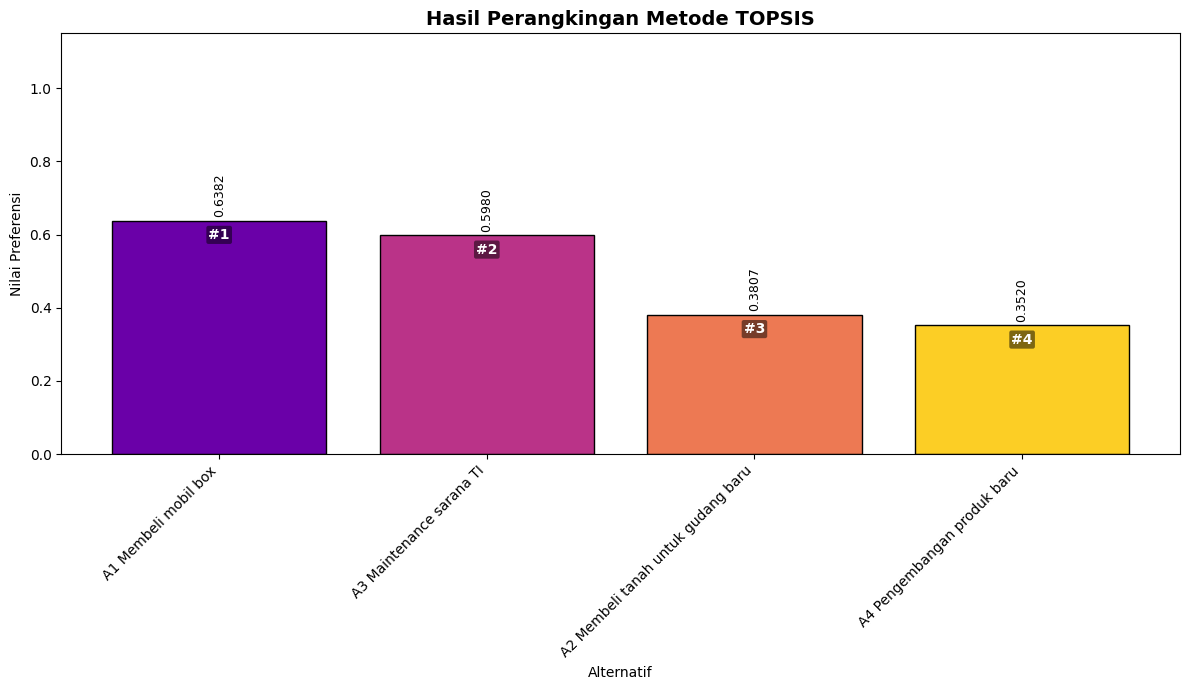

In [18]:
# ============================================================
# TAHAP 17
# VISUALISASI HASIL PERANGKINGAN
# ============================================================

# Jumlah maksimal alternatif yang ditampilkan pada grafik
# (ubah angka ini jika ingin menampilkan lebih sedikit/banyak)
batas_tampil = 15

# Tabel hasil sudah terurut dari nilai terbesar,
# sehingga head() mengambil peringkat teratas
hasil_grafik = hasil.head(batas_tampil)

# Judul grafik menyesuaikan jumlah alternatif yang ditampilkan
if len(hasil) > batas_tampil:
    judul_grafik = f"Hasil Perangkingan Metode TOPSIS (Top {batas_tampil})"
    print(
        f"Grafik hanya menampilkan {batas_tampil} peringkat teratas "
        f"dari {len(hasil)} alternatif."
    )
else:
    judul_grafik = "Hasil Perangkingan Metode TOPSIS"

# Membuat kanvas grafik berukuran 12 x 7 inci
plt.figure(figsize=(12, 7))

# Warna batang bergradasi dari skema warna plasma
warna = plt.cm.plasma(
    np.linspace(0.2, 0.9, len(hasil_grafik))
)

# Grafik batang nilai preferensi tiap alternatif
bars = plt.bar(
    hasil_grafik["Alternatif"].astype(str),
    hasil_grafik["Nilai Preferensi"],
    color=warna,
    edgecolor="black"
)

plt.title(
    judul_grafik,
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Alternatif")
plt.ylabel("Nilai Preferensi")
# Nilai preferensi TOPSIS selalu antara 0 dan 1,
# ruang ekstra di atas disediakan untuk teks nilai
plt.ylim(0, 1.15)
# Memiringkan label sumbu X agar tidak bertumpuk
plt.xticks(rotation=45, ha="right")

# Menulis nilai (tegak, di atas batang) dan peringkat (di dalam batang)
for bar, nilai, peringkat in zip(
    bars,
    hasil_grafik["Nilai Preferensi"],
    hasil_grafik["Peringkat"]
):
    # Nilai preferensi ditulis tegak di atas batang
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.01,
        f"{nilai:.4f}",
        ha="center",
        va="bottom",
        rotation=90,
        fontsize=9
    )

    # Peringkat ditulis singkat di dalam batang
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() - 0.02,
        f"#{peringkat}",
        ha="center",
        va="top",
        fontsize=10,
        fontweight="bold",
        color="white",
        bbox=dict(
            boxstyle="round,pad=0.15",
            facecolor="black",
            alpha=0.5,
            edgecolor="none"
        )
    )

plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# TAHAP 18
# MENYIMPAN DAN MENGUNDUH HASIL EXCEL
# ============================================================

# Nama file keluaran (file lama dengan nama sama akan tertimpa)
nama_file_hasil = "hasil_perhitungan_topsis.xlsx"

# Menulis semua tabel ke satu file Excel, satu sheet per tabel
with pd.ExcelWriter(
    nama_file_hasil,
    engine="openpyxl"
) as writer:

    df_mentah.to_excel(
        writer,
        sheet_name="Data Mentah",
        index=False
    )

    df_topsis.to_excel(
        writer,
        sheet_name="Matriks Keputusan",
        index=False
    )

    tabel_konfigurasi.to_excel(
        writer,
        sheet_name="Konfigurasi Kriteria",
        index=False
    )

    tabel_penyebut.to_excel(
        writer,
        sheet_name="Penyebut Normalisasi",
        index=False
    )

    df_normalisasi.to_excel(
        writer,
        sheet_name="Matriks Normalisasi",
        index=False
    )

    df_rincian_normalisasi.to_excel(
        writer,
        sheet_name="Rincian Normalisasi",
        index=False
    )

    df_terbobot.to_excel(
        writer,
        sheet_name="Matriks Terbobot",
        index=False
    )

    tabel_solusi_ideal.to_excel(
        writer,
        sheet_name="Solusi Ideal",
        index=False
    )

    df_rincian_jarak.to_excel(
        writer,
        sheet_name="Rincian Jarak",
        index=False
    )

    hasil_lengkap.to_excel(
        writer,
        sheet_name="Hasil Perangkingan",
        index=False
    )

print(
    f"Hasil berhasil disimpan sebagai "
    f"'{nama_file_hasil}'."
)

# Mengunduh file hasil ke komputer (khusus Google Colab)
files.download(nama_file_hasil)